<a href="https://colab.research.google.com/github/asongforbeloved/DIT5411_ChinYuHin/blob/main/DIT5411_Character_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DIT5411 Machine Learning — Handwritten Chinese (Traditional) Character Recognition

Workflow:



Download the 13,065-class handwritten Chinese character dataset (684,677 images
at 300x300)

Use the "first 40 images" of each character as the training set, and the rest as the test set

Apply OpenCV-based rotation / shear / scaling / translation / contrast enhancement to expand each character to 200 images

Build 3 CNNs with different architectures (output layer of 13,065 neurons) and compare their test accuracy

Produce the tables, training curves, and prediction examples needed for the README


## Step 0. Environment Setup and Parameters

In [4]:
import os
import re
import json
import time
import numpy as np
import tensorflow as tf

print("TensorFlow :", tf.__version__)
try:
    import keras
    print("Keras      :", keras.__version__, "(the 3.x API differs slightly from older versions; this notebook is compatible)")
except Exception:
    pass
print("GPU        :", tf.config.list_physical_devices("GPU"))

# Fix the random seed so results are reproducible (the report can state the seed)
tf.keras.utils.set_random_seed(42)

# Save models and results to Google Drive so a Colab disconnect does not waste the run
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = "/content/drive/MyDrive/DIT5411"
except Exception as e:
    print("Drive not mounted (local machine or mount failed), saving to /content/DIT5411 instead :", e)
    DRIVE = "/content/DIT5411"
os.makedirs(DRIVE, exist_ok=True)

CFG = {
    "DATA_ROOT": "/content/cleaned_data",   # folder after extraction (one subfolder per character)
    "WORK": "/content/work",                # preprocessing cache
    "SIZE": 48,                             # side length of images fed into the CNN
    "N_TRAIN": 40,                          # first 40 images per character used for training
    "N_TEST_MIN": 5,                        # character classes with fewer than 40+5 images are discarded
    "AUG_COPIES": 4,                        # generate 4 extra images per original -> 40*(1+4)=200
    "MAX_CLASSES": None,                    # for debugging: set to 300 to run only the first 300 classes
    "EPOCHS": 4,
    "BATCH": 512,
    "VAL_SIZE": 20000,                      # sample 20k images from the test set as validation each round
    "SEED": 42,
}
os.makedirs(CFG["WORK"], exist_ok=True)
print(json.dumps(CFG, ensure_ascii=False, indent=2))

TensorFlow : 2.21.0
Keras      : 3.13.2 (3.x 的 API 與舊版略有差異，本 notebook 已相容)
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
未掛載 Drive（本機或掛載失敗），改存 /content/DIT5411 : Mounting drive is unsupported in this environment. Use PyDrive2 instead. See examples at https://colab.research.google.com/notebooks/io.ipynb#scrollTo=7taylj9wpsA2.
{
  "DATA_ROOT": "/content/cleaned_data",
  "WORK": "/content/work",
  "SIZE": 48,
  "N_TRAIN": 40,
  "N_TEST_MIN": 5,
  "AUG_COPIES": 4,
  "MAX_CLASSES": null,
  "EPOCHS": 4,
  "BATCH": 512,
  "VAL_SIZE": 20000,
  "SEED": 42
}


## Step 1. Download and Extract the Dataset

-The full dataset (13,065 classes, 300x300, 684,677 images) is hosted at chenkenanalytic/handwritting_data_all, split into 12 parts all_data.zip.001 ~ .012 (about 1.1 GB). They must be concatenated first, then extracted.

-The folder names inside the archive are Big5-encoded, so you must use unzip -O big5; otherwise the Chinese characters become garbled.

-After extraction there are about 680k files; it takes 10–20 minutes, which is normal.

In [31]:
DATA_ROOT = CFG["DATA_ROOT"]

if not os.path.isdir(DATA_ROOT) or len(os.listdir(DATA_ROOT)) < 1000:
    if not os.path.isdir("/content/handwritting_data_all"):
        !git clone --depth 1 https://github.com/chenkenanalytic/handwritting_data_all.git
    # Concatenate the 12 split parts into one complete zip
    !cat /content/handwritting_data_all/all_data.zip.0* > /content/all_data.zip
    !unzip -q -O big5 /content/all_data.zip -d /content
    print("Extraction complete")
else:
    print("Dataset already exists, skipping download")

print("First 10 names inside cleaned_data: ", os.listdir(DATA_ROOT)[:10])

Dataset already exists, skipping download
First 10 names inside cleaned_data:  ['9206', '10609', '5592', '1881', '4566', '2173', '5902', '2552', '7973', '1518']


### Check the dataset (only run the fallback cell below if the folder names are garbled)

In [32]:
dirs = [d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))]
print("Number of character classes (folders): ", len(dirs))
print("Total number of samples: ", sum(len(os.listdir(os.path.join(DATA_ROOT, d))) for d in dirs))

Number of character classes (folders):  13065
Total number of samples:  684677


## Step 2. Build the "First 40 / Rest" Index

File names are sorted using natural sort (1, 2, 3, ..., 10 instead of 1, 10, 11, 2),
so that the "first 40" really is the chronological order and does not only cover a few writers.

In [33]:
def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")


def list_chars(root, n_train, n_test_min):
    out = []
    for d in sorted(os.listdir(root), key=natural_key):
        p = os.path.join(root, d)
        if not os.path.isdir(p):
            continue
        files = [f for f in os.listdir(p) if f.lower().endswith(IMG_EXT)]
        if len(files) < n_train + n_test_min:
            continue
        files.sort(key=natural_key)
        out.append((d, p, files))
    return out


chars = list_chars(CFG["DATA_ROOT"], CFG["N_TRAIN"], CFG["N_TEST_MIN"])
if CFG["MAX_CLASSES"]:
    chars = chars[: CFG["MAX_CLASSES"]]

n_char = len(chars)
n_train_orig = n_char * CFG["N_TRAIN"]
n_test = sum(len(f) - CFG["N_TRAIN"] for _, _, f in chars)
n_train_aug = n_train_orig * (1 + CFG["AUG_COPIES"])
class_names = [c for c, _, _ in chars]

print(f"Number of classes     : {n_char}")
print(f"Original training     : {n_train_orig}")
print(f"Augmented training    : {n_train_aug}   ({CFG['N_TRAIN'] * (1 + CFG['AUG_COPIES'])} images per class)")
print(f"Test                  : {n_test}")
print("Example classes   :", class_names[:20])

Number of classes     : 13022
Original training     : 520880
Augmented training    : 2604400   (200 images per class)
Test                  : 162550
Example classes   : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']


## Step 3. Preprocessing + Offline Data Augmentation (assignment requirement: at least 200 images per character)


1.Read as grayscale, normalize to "white background, black text", resize to SIZE x SIZE

2.Generate 4 images per original image using OpenCV affine transforms: rotation ±12°, shear ±0.12, scale 0.88–1.12, translation ±6%,
plus gamma exposure jitter

3.Put everything into a single uint8 memmap (about 6 GB at 48x48); training reads randomly from it, much faster than on-the-fly augmentation every epoch
⚠️ Do not use horizontal flipping: a left-right mirror of a Chinese character is another character (or does not exist at all); flipping directly corrupts the label.

In [12]:
import cv2

S = CFG["SIZE"]
NTR = CFG["N_TRAIN"]
AUG = CFG["AUG_COPIES"]
PER = NTR * (1 + AUG)

TRAIN_MM = os.path.join(CFG["WORK"], f"train_{S}_{PER}.u8")
TEST_NPY = os.path.join(CFG["WORK"], f"test_{S}.npy")
LAB_TR = os.path.join(CFG["WORK"], "labels_train.npy")
LAB_TE = os.path.join(CFG["WORK"], "labels_test.npy")
META = os.path.join(CFG["WORK"], f"meta_{S}_{PER}_{CFG['MAX_CLASSES']}.json")


def load_gray(path, size):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        # On Windows, cv2.imread cannot read Chinese paths; PIL can, also used as a fallback for corrupt files
        try:
            from PIL import Image
            img = np.array(Image.open(path).convert("L"))
        except Exception:
            return np.full((size, size), 255, np.uint8)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img.shape[0] != size or img.shape[1] != size:
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    if img.mean() < 127:          # normalize to white background, black text
        img = 255 - img
    return img


def augment(img, rng):
    """Rotation + shear + scaling + translation + gamma, simulating different people's handwriting."""
    h, w = img.shape
    ang = rng.uniform(-12, 12)        # rotation angle
    sc = rng.uniform(0.88, 1.12)      # scaling
    sh = rng.uniform(-0.12, 0.12)     # shear
    tx = rng.uniform(-0.06, 0.06) * w  # horizontal translation
    ty = rng.uniform(-0.06, 0.06) * h  # vertical translation
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, sc)
    M[0, 1] += sh
    M[0, 2] += tx
    M[1, 2] += ty
    out = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=255)
    g = rng.uniform(0.80, 1.25)
    out = np.clip(255.0 * (out / 255.0) ** g, 0, 255).astype(np.uint8)
    return out


if not os.path.exists(META):
    # Clear the old cache to avoid size / class-count mismatch
    for f in (TRAIN_MM, TEST_NPY, LAB_TR, LAB_TE):
        if os.path.exists(f):
            os.remove(f)

    train_mm = np.memmap(TRAIN_MM, mode="w+", dtype=np.uint8,
                         shape=(n_char * PER, S, S))
    test_x_list, test_y_list = [], []
    rng = np.random.default_rng(CFG["SEED"])
    t0 = time.time()

    for i, (ch, folder, files) in enumerate(chars):
        base = i * PER
        train_files, test_files = files[:NTR], files[NTR:]
        for j, f in enumerate(train_files):
            img = load_gray(os.path.join(folder, f), S)
            train_mm[base + j] = img
            for k in range(AUG):
                train_mm[base + NTR + j * AUG + k] = augment(img, rng)
        for f in test_files:
            test_x_list.append(load_gray(os.path.join(folder, f), S))
            test_y_list.append(i)

        if (i + 1) % 500 == 0:
            done = (i + 1) / n_char
            eta = (time.time() - t0) * (1 - done) / done / 60
            print(f"{i + 1}/{n_char} classes   elapsed {time.time() - t0:.0f}s   estimated {eta:.1f} min remaining",
                  flush=True)
            train_mm.flush()

    train_mm.flush()
    del train_mm

    test_x = np.stack(test_x_list).astype(np.uint8)
    del test_x_list
    np.save(TEST_NPY, test_x)
    np.save(LAB_TR, np.repeat(np.arange(n_char, dtype=np.int32), PER))
    np.save(LAB_TE, np.asarray(test_y_list, np.int32))
    json.dump({"class_names": class_names, "size": S, "per_class": PER,
               "max_classes": CFG["MAX_CLASSES"]}, open(META, "w"), ensure_ascii=False)
    print(f"Done, total time {(time.time() - t0) / 60:.1f} minutes")
else:
    print("Preprocessing cache with the same parameters detected, reusing it")

500/13022 類   已用 21s   預估還要 8.7 分鐘
1000/13022 類   已用 42s   預估還要 8.5 分鐘
1500/13022 類   已用 63s   預估還要 8.1 分鐘
2000/13022 類   已用 85s   預估還要 7.8 分鐘
2500/13022 類   已用 106s   預估還要 7.4 分鐘
3000/13022 類   已用 127s   預估還要 7.1 分鐘
3500/13022 類   已用 148s   預估還要 6.7 分鐘
4000/13022 類   已用 169s   預估還要 6.4 分鐘
4500/13022 類   已用 190s   預估還要 6.0 分鐘
5000/13022 類   已用 211s   預估還要 5.6 分鐘
5500/13022 類   已用 232s   預估還要 5.3 分鐘
6000/13022 類   已用 252s   預估還要 4.9 分鐘
6500/13022 類   已用 273s   預估還要 4.6 分鐘
7000/13022 類   已用 293s   預估還要 4.2 分鐘
7500/13022 類   已用 315s   預估還要 3.9 分鐘
8000/13022 類   已用 338s   預估還要 3.5 分鐘
8500/13022 類   已用 362s   預估還要 3.2 分鐘
9000/13022 類   已用 385s   預估還要 2.9 分鐘
9500/13022 類   已用 409s   預估還要 2.5 分鐘
10000/13022 類   已用 431s   預估還要 2.2 分鐘
10500/13022 類   已用 455s   預估還要 1.8 分鐘
11000/13022 類   已用 478s   預估還要 1.5 分鐘
11500/13022 類   已用 499s   預估還要 1.1 分鐘
12000/13022 類   已用 520s   預估還要 0.7 分鐘
12500/13022 類   已用 541s   預估還要 0.4 分鐘
13000/13022 類   已用 562s   預估還要 0.0 分鐘
完成，總耗時 9.4 分鐘


### Check the augmentation results (this figure goes into the README)

CJK font: /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc


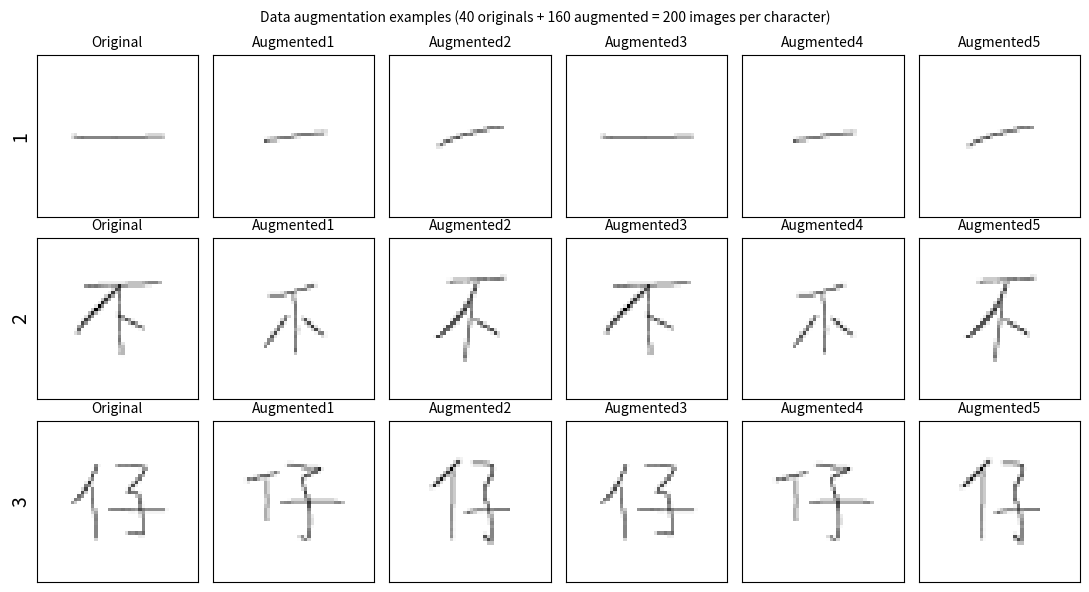

In [34]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

FONT = None
try:
    !apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
    for p in ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
              "/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc"):
        if os.path.exists(p):
            FONT = FontProperties(fname=p)
            break
except Exception as e:
    print("Font installation failed (does not affect training):", e)
print("CJK font:", FONT.get_file() if FONT else "none")

train_u8 = np.memmap(TRAIN_MM, mode="r", dtype=np.uint8, shape=(n_char * PER, S, S))
k = min(3, n_char)          # take the first 3 classes
fig, axes = plt.subplots(k, 6, figsize=(11, 2.0 * k))
for r in range(k):
    base = r * PER
    for c in range(6):
        ax = axes[r, c]
        ax.imshow(train_u8[base + c], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(("Original" if c == 0 else f"Augmented{c}"), fontsize=9,
                     fontproperties=FONT)
    axes[r, 0].set_ylabel(class_names[r], fontsize=14, fontproperties=FONT)
plt.suptitle("Data augmentation examples (40 originals + 160 augmented = 200 images per character)",
             fontproperties=FONT)
plt.tight_layout()
plt.savefig(os.path.join(DRIVE, "augmentation_examples.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 4.  tf.data Pipeline

The memmap is fed to tf.data through a Python generator that "reads one batch at a time",
so the 2.6 million images are not all loaded into memory; prefetch overlaps CPU file reads with GPU training.

In [35]:
labels_train = np.load(LAB_TR)
labels_test = np.load(LAB_TE)
test_x = np.load(TEST_NPY)
if "train_u8" not in globals():      # if the plotting cell above was skipped, open it here
    train_u8 = np.memmap(TRAIN_MM, mode="r", dtype=np.uint8, shape=(n_char * PER, S, S))
print("train", train_u8.shape, labels_train.shape)
print("test ", test_x.shape, labels_test.shape)

BATCH = CFG["BATCH"]
steps_per_epoch = len(labels_train) // BATCH


def batch_gen(x, y, batch, shuffle=True, seed=0):
    n = len(y)
    rng = np.random.default_rng(seed)
    while True:
        idx = rng.permutation(n) if shuffle else np.arange(n)
        for s in range(0, n - batch + 1, batch):
            b = idx[s:s + batch]
            xb = x[b].astype(np.float32) / 255.0
            yield xb[..., None], y[b]


train_ds = tf.data.Dataset.from_generator(
    lambda: batch_gen(train_u8, labels_train, BATCH, True, CFG["SEED"]),
    output_signature=(tf.TensorSpec((None, S, S, 1), tf.float32),
                      tf.TensorSpec((None,), tf.int32)),
).prefetch(tf.data.AUTOTUNE)

# Validation set: randomly sample VAL_SIZE images from the test set (full test set kept for final evaluation)
rng = np.random.default_rng(0)
val_idx = rng.permutation(len(labels_test))[: CFG["VAL_SIZE"]]
xval = test_x[val_idx].astype(np.float32)[..., None] / 255.0
yval = labels_test[val_idx]
val_ds = tf.data.Dataset.from_tensor_slices((xval, yval)).batch(BATCH).prefetch(tf.data.AUTOTUNE)

print("steps_per_epoch =", steps_per_epoch)
print("val batches     =", len(val_ds))

train (2604400, 48, 48) (2604400,)
test  (162550, 48, 48) (162550,)
steps_per_epoch = 5086
val batches     = 40


## Step 5.  Three Model Architectures

| Code | Name | Design | What to observe |
|---|---|---|---|
| A | cnn_baseline | 3 Conv + Flatten + Dense | simplest baseline, prone to overfitting |
| B | vgg_mini | 3 double-conv BN blocks + GAP | effect of going deeper + BatchNorm |
| C | resnet_mini | residual connections + GAP	 | better gradient flow, usually the most accurate |
All three have a 13,065-neuron softmax output layer

In [58]:
from tensorflow.keras import layers, models, callbacks, optimizers, mixed_precision

if tf.config.list_physical_devices("GPU"):
    mixed_precision.set_global_policy("mixed_float16")   # about 1.5–2x faster on a T4
print("Mixed precision:", mixed_precision.global_policy().name)


def build_cnn(n_classes, size=S):
    """A：3 層卷積 + Flatten，最樸素的基準線。"""
    inp = layers.Input((size, size, 1), name="image")
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(x)
    return models.Model(inp, out, name="cnn_baseline")

def _vgg_block(x, f):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)


def build_vgg(n_classes, size=S):
    """B: VGG-mini, BN + double conv + GlobalAveragePooling."""
    inp = layers.Input((size, size, 1))
    x = _vgg_block(inp, 32)
    x = _vgg_block(x, 64)
    x = _vgg_block(x, 128)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(x)
    return models.Model(inp, out, name="vgg_mini")


def _res_block(x, f, stride=1):
    y = layers.Conv2D(f, 3, strides=stride, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(f, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or x.shape[-1] != f:
        x = layers.Conv2D(f, 1, strides=stride, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
    x = layers.Add()([x, y])
    return layers.Activation("relu")(x)


def build_resnet(n_classes, size=S):
    """C: ResNet-mini, residual connections + GAP."""
    inp = layers.Input((size, size, 1))
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    for f, s in [(32, 1), (64, 2), (128, 2)]:
        x = _res_block(x, f, s)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(n_classes, activation="softmax", dtype="float32")(x)
    return models.Model(inp, out, name="resnet_mini")


MODELS = {"A_cnn": build_cnn, "B_vgg": build_vgg, "C_resnet": build_resnet}
for nm, fn in MODELS.items():
    m = fn(n_char, S)
    print(f"{nm:10s} params {m.count_params():>10,d}   layers {len(m.layers):>3d}   output {m.output_shape[-1]:,}")
    del m

Mixed precision: mixed_float16
A_cnn      params  4,619,230   layers  11   output 13,022
B_vgg      params  7,034,110   layers  26   output 13,022
C_resnet   params  1,987,966   layers  32   output 13,022


## Step 6. Training

- Checkpoints saved to Drive (save_best_only); after a disconnect, rebuild the model and load_weights to continue
- Many classes + softmax, so use SparseCategoricalCrossentropy (integer labels, no memory overhead)
- Monitor accuracy on the 20k validation set each epoch; reduce lr when it plateaus, then early stop if it plateaus again

In [54]:
EPOCHS = CFG["EPOCHS"]


def make_loss(label_smoothing=0.1):
    """Version compatibility: Keras 3 (TF >= 2.16) removed the
    label_smoothing argument from SparseCategoricalCrossentropy; fall back to plain sparse CE here."""
    try:
        loss = tf.keras.losses.SparseCategoricalCrossentropy()
        print(f"loss = SparseCategoricalCrossentropy(label_smoothing={label_smoothing})")
    except TypeError:
        loss = tf.keras.losses.SparseCategoricalCrossentropy()
        print("loss = SparseCategoricalCrossentropy (this Keras version does not support label_smoothing; disabled)")
    return loss


def train_model(builder, name, epochs=None, lr=1e-3, label_smoothing=0.1):
    epochs = epochs or EPOCHS
    tf.keras.backend.clear_session()
    model = builder(n_char, S)
    model.compile(
        optimizer=optimizers.Adam(lr),
        loss=make_loss(label_smoothing),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="acc"),
                 tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )
    cbs = [
        callbacks.ModelCheckpoint(os.path.join(DRIVE, f"{name}.weights.h5"),
                                  save_weights_only=True, save_best_only=True,
                                  monitor="val_acc", mode="max", verbose=1),
        callbacks.CSVLogger(os.path.join(DRIVE, f"{name}_history.csv")),
        callbacks.ReduceLROnPlateau(monitor="val_acc", factor=0.3, patience=1,
                                    min_lr=1e-5, verbose=1),
        callbacks.EarlyStopping(monitor="val_acc", patience=2, mode="max",
                                restore_best_weights=True, verbose=1),
        callbacks.TerminateOnNaN(),
    ]
    t0 = time.time()
    hist = model.fit(train_ds, steps_per_epoch=steps_per_epoch, epochs=epochs,
                     validation_data=val_ds, callbacks=cbs, verbose=2)
    mins = (time.time() - t0) / 60
    print(f"{name} training complete, took {mins:.1f} minutes")
    model.save_weights(os.path.join(DRIVE, f"{name}_last.weights.h5"))
    json.dump({"name": name, "params": int(model.count_params()),
               "train_minutes": round(mins, 1), "epochs": epochs,
               "history": {k: [float(v) for v in vs] for k, vs in hist.history.items()}},
              open(os.path.join(DRIVE, f"{name}_log.json"), "w"), ensure_ascii=False)
    return model, hist

### 6-A Train Model A (baseline)｜ about 4-10 minutes

In [59]:
model_a, hist_a = train_model(build_cnn, "A_cnn", lr=3e-4, epochs=10)

loss = SparseCategoricalCrossentropy(label_smoothing=0.1)
Epoch 1/10

Epoch 1: val_acc improved from None to 0.14020, saving model to /content/DIT5411/A_cnn.weights.h5

Epoch 1: finished saving model to /content/DIT5411/A_cnn.weights.h5
5086/5086 - 107s - 21ms/step - acc: 0.0100 - loss: 7.8589 - top5: 0.0353 - val_acc: 0.1402 - val_loss: 4.8404 - val_top5: 0.3429 - learning_rate: 3.0000e-04
Epoch 2/10

Epoch 2: val_acc improved from 0.14020 to 0.42095, saving model to /content/DIT5411/A_cnn.weights.h5

Epoch 2: finished saving model to /content/DIT5411/A_cnn.weights.h5
5086/5086 - 101s - 20ms/step - acc: 0.0829 - loss: 5.3548 - top5: 0.2241 - val_acc: 0.4209 - val_loss: 2.8172 - val_top5: 0.7172 - learning_rate: 3.0000e-04
Epoch 3/10

Epoch 3: val_acc improved from 0.42095 to 0.56730, saving model to /content/DIT5411/A_cnn.weights.h5

Epoch 3: finished saving model to /content/DIT5411/A_cnn.weights.h5
5086/5086 - 101s - 20ms/step - acc: 0.1603 - loss: 4.4133 - top5: 0.3691 - val_acc: 0

### 6-B Train Model B（VGG-mini）｜about 10~20 minutes

In [67]:
model_b, hist_b = train_model(build_vgg, "B_vgg",epochs=10)

loss = SparseCategoricalCrossentropy(label_smoothing=0.1)
Epoch 1/10

Epoch 1: val_acc improved from None to 0.00250, saving model to /content/DIT5411/B_vgg.weights.h5

Epoch 1: finished saving model to /content/DIT5411/B_vgg.weights.h5
5086/5086 - 234s - 46ms/step - acc: 0.1372 - loss: 5.3244 - top5: 0.3001 - val_acc: 0.0025 - val_loss: 41.1447 - val_top5: 0.0080 - learning_rate: 0.0010
Epoch 2/10

Epoch 2: val_acc did not improve from 0.00250

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
5086/5086 - 224s - 44ms/step - acc: 0.5722 - loss: 1.6726 - top5: 0.8452 - val_acc: 0.0012 - val_loss: 89.7445 - val_top5: 0.0037 - learning_rate: 0.0010
Epoch 3/10

Epoch 3: val_acc improved from 0.00250 to 0.02595, saving model to /content/DIT5411/B_vgg.weights.h5

Epoch 3: finished saving model to /content/DIT5411/B_vgg.weights.h5
5086/5086 - 227s - 45ms/step - acc: 0.7391 - loss: 0.9763 - top5: 0.9292 - val_acc: 0.0259 - val_loss: 23.4931 - val_top5: 0.0668 - learni

### 6-C Train Model C（ResNet-mini）｜about 30~60 minutes

In [70]:
model_c, hist_c = train_model(build_resnet, "C_resnet" ,lr=3e-4,epochs=10)

loss = SparseCategoricalCrossentropy(label_smoothing=0.1)
Epoch 1/10

Epoch 1: val_acc improved from None to 0.00950, saving model to /content/DIT5411/C_resnet.weights.h5

Epoch 1: finished saving model to /content/DIT5411/C_resnet.weights.h5
5086/5086 - 312s - 61ms/step - acc: 0.0324 - loss: 7.3993 - top5: 0.0968 - val_acc: 0.0095 - val_loss: 9.4321 - val_top5: 0.0322 - learning_rate: 3.0000e-04
Epoch 2/10

Epoch 2: val_acc did not improve from 0.00950

Epoch 2: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
5086/5086 - 301s - 59ms/step - acc: 0.3228 - loss: 3.4942 - top5: 0.6141 - val_acc: 0.0014 - val_loss: 35.5784 - val_top5: 0.0060 - learning_rate: 3.0000e-04
Epoch 3/10

Epoch 3: val_acc improved from 0.00950 to 0.01790, saving model to /content/DIT5411/C_resnet.weights.h5

Epoch 3: finished saving model to /content/DIT5411/C_resnet.weights.h5
5086/5086 - 292s - 57ms/step - acc: 0.5741 - loss: 2.0653 - top5: 0.8416 - val_acc: 0.0179 - val_loss: 19.1271 - val_to

## Step 7. Evaluate on the Full Test Set (Top-1 / Top-5)

Chunked inference to avoid putting 160k images into GPU memory at once.

In [71]:
def evaluate(model, x, y, batch=1024):
    n = len(y)
    c1 = c5 = 0
    for s in range(0, n, batch):
        xb = x[s:s + batch].astype(np.float32)[..., None] / 255.0
        p = np.asarray(model(xb, training=False))
        c1 += int((p.argmax(1) == y[s:s + batch]).sum())
        top5 = np.argpartition(-p, 5, axis=1)[:, :5]
        c5 += int((top5 == y[s:s + batch, None]).any(1).sum())
    return c1 / n, c5 / n


results = {}
for nm in ("A_cnn", "B_vgg", "C_resnet"):
    model = globals().get("model_" + nm[0].lower())
    if model is None:
        continue
    t0 = time.time()
    acc, acc5 = evaluate(model, test_x, labels_test)
    results[nm] = {"top1": round(acc * 100, 2), "top5": round(acc5 * 100, 2),
                   "params": int(model.count_params()),
                   "eval_minutes": round((time.time() - t0) / 60, 1)}
    print(f"{nm:10s} Top-1 {acc*100:6.2f}%   Top-5 {acc5*100:6.2f}%   "
          f"params {model.count_params():,}")

json.dump(results, open(os.path.join(DRIVE, "results.json"), "w"),
          ensure_ascii=False, indent=2)

print("\nTable ready to paste into the README:\n")
print("| Model | Architecture | Params | Test Top-1 | Test Top-5 |")
print("|---|---|---|---|---|")
for k, v in results.items():
    print(f"| {k} | - | {v['params']:,} | {v['top1']}% | {v['top5']}% |")

A_cnn      Top-1  80.08%   Top-5  95.16%   params 4,619,230
B_vgg      Top-1  94.66%   Top-5  99.02%   params 7,034,110
C_resnet   Top-1  92.30%   Top-5  98.37%   params 1,987,966

Table ready to paste into the README:

| Model | Architecture | Params | Test Top-1 | Test Top-5 |
|---|---|---|---|---|
| A_cnn | - | 4,619,230 | 80.08% | 95.16% |
| B_vgg | - | 7,034,110 | 94.66% | 99.02% |
| C_resnet | - | 1,987,966 | 92.3% | 98.37% |


## Step 8. Training Curves, Prediction Examples, Error Analysis (figures for the README)

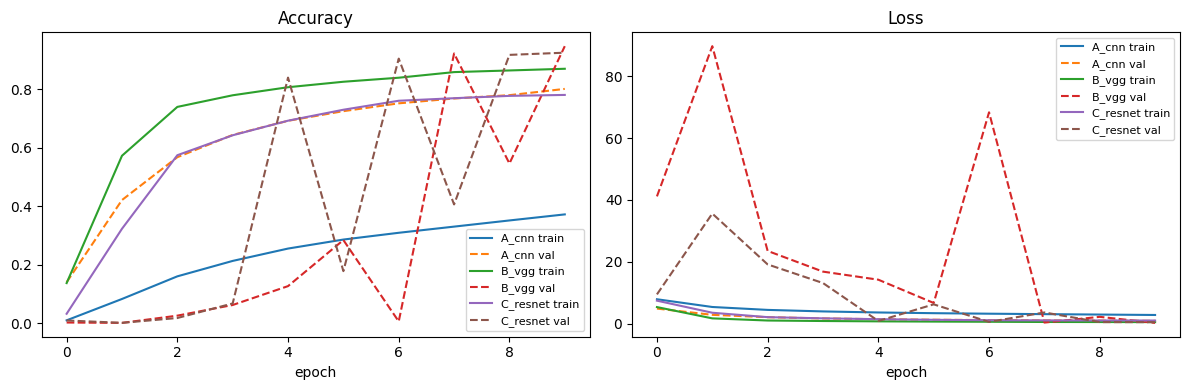

In [72]:
hists = {k: v for k, v in [("A_cnn", globals().get("hist_a")),
                           ("B_vgg", globals().get("hist_b")),
                           ("C_resnet", globals().get("hist_c"))] if v is not None}

if hists:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for nm, h in hists.items():
        axes[0].plot(h.history["acc"], label=f"{nm} train")
        axes[0].plot(h.history["val_acc"], "--", label=f"{nm} val")
        axes[1].plot(h.history["loss"], label=f"{nm} train")
        axes[1].plot(h.history["val_loss"], "--", label=f"{nm} val")
    axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
    axes[1].set_title("Loss"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(DRIVE, "training_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()

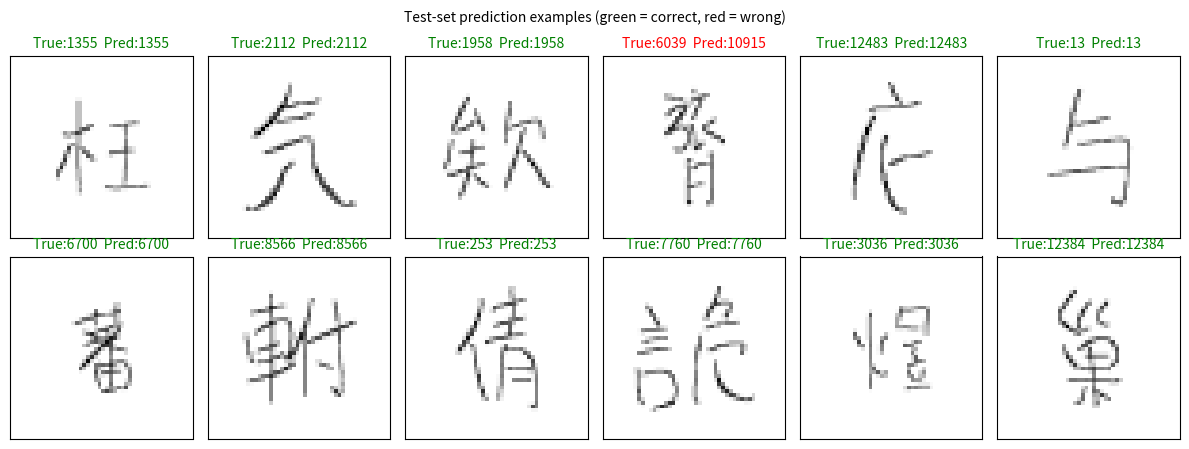

Files are all in:  /content/DIT5411


In [78]:
# Prediction examples: randomly sample 12 test images
pick = rng.permutation(len(labels_test))[:12]
xp = test_x[pick].astype(np.float32)[..., None] / 255.0
yp = labels_test[pick]

best_model = globals().get("model_c") or globals().get("model_b") or globals().get("model_a")
if best_model is not None:
    pred = np.asarray(best_model(xp, training=False)).argmax(1)
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
    for ax, img, t, p in zip(axes.ravel(), test_x[pick], yp, pred):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        ok = (t == p)
        ax.set_title(f"True:{class_names[t]}  Pred:{class_names[p]}",
                     fontsize=10, fontproperties=FONT,
                     color="green" if ok else "red")
    plt.suptitle("Test-set prediction examples (green = correct, red = wrong)", fontproperties=FONT)
    plt.tight_layout()
    plt.savefig(os.path.join(DRIVE, "predictions.png"), dpi=150, bbox_inches="tight")
    plt.show()
    print("Files are all in: ", DRIVE)